# Практика оценки модели: Кредитный скоринг

**Курс:** Метрики и валидация моделей | **Время:** ~60 минут

Вы — ML-инженер в банке. Коллега обучил три модели для задачи кредитного скоринга. Ваша задача — оценить их качество, выявить проблемы и дать рекомендацию.

| Часть | Задача | Баллы |
|-------|--------|-------|
| 1 | Загрузка данных и анализ баланса классов | 15 |
| 2 | Расчёт метрик | 25 |
| 3 | Визуализация и интерпретация | 25 |
| 4 | Диагностика проблем | 25 |
| 5 | Итоговое заключение | 10 |

> Ячейки с `# TODO` — ваш код. Остальные — просто запустите.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)

import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
sns.set_style('whitegrid')

---
## Часть 1. Загрузка данных (15 баллов)

In [2]:
X_raw, y_raw = make_classification(
    n_samples=5000, n_features=15, n_informative=8, n_redundant=3,
    n_clusters_per_class=2, weights=[0.85, 0.15], flip_y=0.02, random_state=42
)

feature_names = [
    'age', 'income', 'credit_history_length', 'num_credit_cards',
    'num_loans', 'loan_amount', 'monthly_payment', 'debt_to_income',
    'employment_years', 'savings_balance', 'checking_balance',
    'num_late_payments', 'credit_utilization', 'num_inquiries', 'collateral_value'
]

df = pd.DataFrame(X_raw, columns=feature_names)
df['target'] = y_raw  # 0 = вернули кредит, 1 = дефолт

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

df.head()

,age,income,credit_history_length,num_credit_cards,num_loans,loan_amount,monthly_payment,debt_to_income,employment_years,savings_balance,checking_balance,num_late_payments,credit_utilization,num_inquiries,collateral_value,target
0,-2.049293,3.615483,3.118878,2.005720,-2.064284,-0.460428,0.934882,0.646521,-0.780696,1.282279,-6.325218,1.499781,-3.566147,-3.152740,0.852194,1
1,-0.456544,1.167085,-0.045162,0.032667,2.158686,2.404887,3.265818,2.654924,-0.034245,-3.969590,-1.101600,0.537369,-3.340452,-1.647374,-0.000631,0
2,-0.761455,-3.439003,0.974781,-0.929408,0.036048,0.490574,0.983861,4.867906,1.421150,4.501390,-0.861753,1.170641,-2.119500,0.370599,3.958159,1
3,-0.924496,3.236780,1.248359,1.717591,-3.780833,-0.553068,2.270066,1.346327,-0.848709,3.264175,2.450091,0.660797,0.923435,1.092604,-1.192920,0
4,-1.825610,-0.246317,1.196458,0.162813,-0.441645,1.942319,0.282601,2.344833,1.767442,-0.587318,1.503137,0.364607,-0.802117,2.115492,-0.789386,0


### 1.1 Анализ баланса классов

> **TODO (5 баллов):** Выведите количество и долю каждого класса, постройте bar plot, прокомментируйте результат.

target
0    4220
1     780
Name: count, dtype: int64
target
0    84.4
1    15.6
Name: proportion, dtype: float64


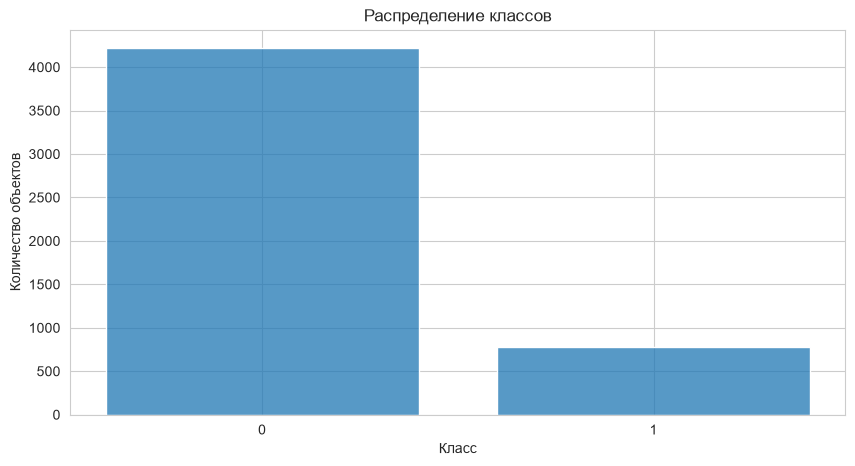

In [3]:
# TODO
# смотрим кол-во каждого класса 
df['target'].value_counts()
print(df['target'].value_counts())

# долю каждого класса
df['target'].value_counts(normalize=True) * 100
print(df['target'].value_counts(normalize=True) * 100)



# строим bar plot
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="target",
    discrete=True,
    kde=False,
    shrink=0.8
)

plt.xticks([0, 1])
plt.title("Распределение классов")
plt.xlabel("Класс")
plt.ylabel("Количество объектов")
plt.show()
# Вывод: Мы видим явный дисбаланс классов. Для кредитного скоринга это может означать. Если класс 0- это вернули кредит, а класс 1 не вернули- то 84.4% 
# пользователей вернули кредит, 15.6% пользователей не вернули.




### 1.2 Обучение моделей

In [4]:
model_a = LogisticRegression(random_state=42, max_iter=1000)
model_a.fit(X_train, y_train)

model_b = RandomForestClassifier(n_estimators=100, random_state=42)
model_b.fit(X, y)

model_c = GradientBoostingClassifier(
    n_estimators=500, max_depth=10, learning_rate=0.5, min_samples_leaf=1, random_state=42
)
model_c.fit(X_train, y_train)

models = {'Модель A (LogReg)': model_a, 'Модель B (RF)': model_b, 'Модель C (GBM)': model_c}
print('Модели обучены')

Модели обучены


---
## Часть 2. Расчёт метрик (25 баллов)

### 2.1 Обоснование выбора метрик

> **TODO (5 баллов):** Почему accuracy вводит в заблуждение при дисбалансе классов? Какие метрики важнее всего для кредитного скоринга? Когда важнее Precision, а когда — Recall?

** Ваш ответ:**
accuracy вводит в заблуждение при дисбалансе классов когда выбирает простую стратегию всегда говорить к примеру нет мошенничества или все письма не спам, если модель обучена распознавать спам и не спам письма. 
К примеру для кредитного скорринга 9900 порядочных заемщиков и 100 неплательщиков, если мы разделим 9900/10000 у нас получится 0,99 то есть точность модели 99%. Но модель не нашла ни одной мошеннической операции, поэтому несмотря на высокий показатель точности, модель бесполезна. 
Для кредитного скорринга важнее Recall (полнота). Recall важен когда пропуск кретичен, например пропустить недобросовестного заемщика или мошенничество и выдать кредит, или пропустить редкое заболевание. Precision (точность по классу) важнее когда ложно положительные срабатывания дорого обходятся. Например пометить важное письмо как спам. Такой подход может дорого обойтись особенно если письмо судебное или несет финансовый или юридический контекст. 

### 2.2 Вычисление метрик

> **TODO (15 баллов):** Для каждой модели вычислите на тестовой выборке Accuracy, Precision, Recall, F1, ROC-AUC. Выведите итоговую таблицу.

In [5]:
results = {}

for name, model in models.items():
    y_pred = model.predict(X_test)  # TODO
    y_prob = model.predict_proba(X_test)[:, 1] # TODO
    results[name] = {
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0), # zero_division=0 означает: «Если при расчёте Precision получается деление на ноль, вернуть значение 0
        'Recall':    recall_score(y_test, y_pred, zero_division=0),
        'F1':        f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC':   roc_auc_score(y_test, y_prob),
    }

pd.DataFrame(results).T.round(4)

# pd - сокращенное название библиотеки pandas
# DataFrame - создает таблицу 
# (results) круглые скобки означают вызов, а внутри мы передаём наш словарь results, где записаны метрики моделей
# . — обращаемся к созданной таблице.
# T — меняет строки и столбцы местами: модели становятся строками, а метрики — столбцами. Так удобнее сравнивать модели.
#     У T нет круглых скобок — пишем именно .T, а не .T().
#  .round(4)   . — обращаемся к таблице после перестановки строк и столбцов.
#              round — округляет числа.
# (4) — указывает, сколько знаков оставить после запятой

,Accuracy,Precision,Recall,F1,ROC-AUC
Модель A (LogReg),0.9104,0.9278,0.4615,0.6164,0.8235
Модель B (RF),1.0000,1.0000,1.0000,1.0000,1.0000
Модель C (GBM),0.9640,0.9630,0.8000,0.8739,0.9589


### 2.3 Classification Report

> **TODO (5 баллов):** Выведите `classification_report` для каждой модели. Сосредоточьтесь на метриках класса `1`.

In [6]:
for name, model in models.items():
    print(f'\n--- {name} ---')
    y_pred = model.predict(X_test)
    print(classification_report(y_test, y_pred, digits=4))
    #digits=4 задает количество знаков (цифр) после запятой при выводе отчета classification_report
    # TODO


--- Модель A (LogReg) ---
              precision    recall  f1-score   support

           0     0.9089    0.9934    0.9493      1055
           1     0.9278    0.4615    0.6164       195

    accuracy                         0.9104      1250
   macro avg     0.9184    0.7275    0.7829      1250
weighted avg     0.9119    0.9104    0.8974      1250


--- Модель B (RF) ---
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      1055
           1     1.0000    1.0000    1.0000       195

    accuracy                         1.0000      1250
   macro avg     1.0000    1.0000    1.0000      1250
weighted avg     1.0000    1.0000    1.0000      1250


--- Модель C (GBM) ---
              precision    recall  f1-score   support

           0     0.9642    0.9943    0.9790      1055
           1     0.9630    0.8000    0.8739       195

    accuracy                         0.9640      1250
   macro avg     0.9636    0.8972    0.9265      1250


---
## Часть 3. Визуализация и интерпретация (25 баллов)

### 3.1 Confusion Matrix

> **TODO (10 баллов):** Постройте матрицы ошибок для трёх моделей (1×3 subplots). Какой тип ошибки (FP или FN) критичнее для банка?

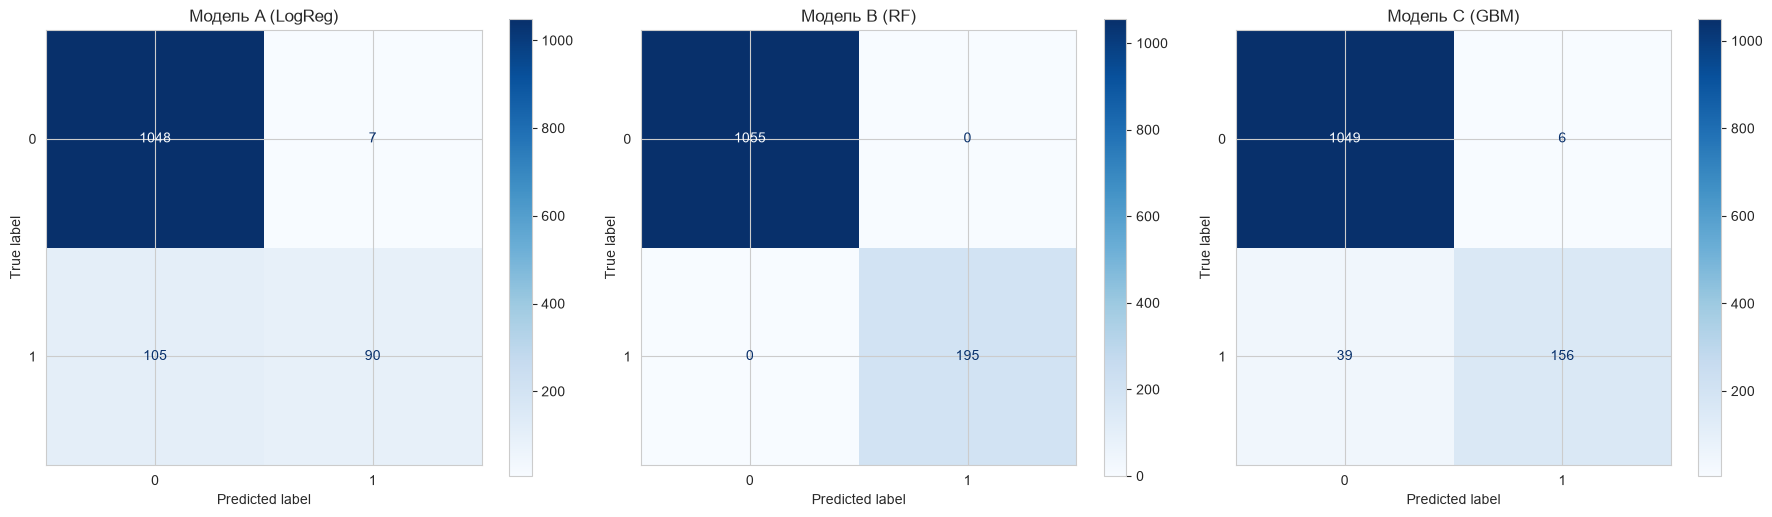

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, model) in zip(axes, models.items()):
    # TODO
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap='Blues')    
    ax.set_title(name)

plt.tight_layout()
plt.show()


**Анализ:**
Модель C (GBM) — лучшая рабочая модель:Она находит 156 из 195 должников (Recall = 80.0%), допуская всего 6 ложных тревог среди 1055 добросовестных клиентов (Precision = 96.3%). 
При необходимости сократить пропуск оставшихся 39 неплательщиков на ней можно просто снизить порог классификации (с 0.5 до 0.3–0.4), повысив полноту выявления дефолтов.

Модель B (Random Forest) — неприменима из-за аномалии:Формально она показывает 100% угадывание (AUC = 1.0, Recall = 100%, Precision = 100%), но в машинном обучении такой результат свидетельствует о грубой ошибке: переобучении, утечке данных (data leakage) или оценке на обучающей выборке вместо теста. На реальных потоках новых клиентов эта модель почти наверняка покажет резкий спад качества.

Модель A (Логистическая регрессия) — опасна для банка:Она пропускает 105 должников из 195 (Recall = 46.15%). Модель одобряет кредиты более чем половине проблемных заёмщиков, что неизбежно приведет к прямым финансовым убыткам.
FN для банка критичнее, чем FP. При ошибке FN модель помечает неблагонадежного заемщика или потенциального банкрота (класс 1) как добросовестного клиента (класс 0). В результате банк выдает кредит неплательщику и теряет всю сумму основного долга вместе с процентами, что приводит к прямому финансовому убытку. При ошибке FP (False Positive — ложноположительная, ошибка I рода) модель ошибочно принимает надежного клиента за должника и отказывает ему в кредите. В этом случае банк теряет лишь потенциальную прибыль от процентов, но сохраняет свои деньги в безопасности.

...

### 3.2 ROC-кривые

> **TODO (10 баллов):** Постройте ROC-кривые всех трёх моделей на одном графике. Добавьте линию случайного классификатора, AUC в легенду, подпишите оси.

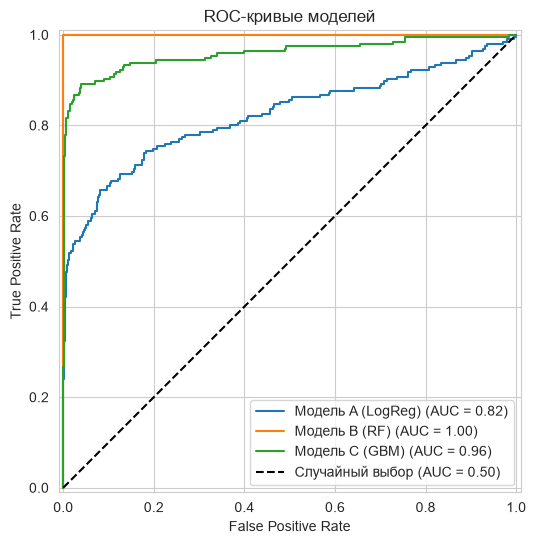

In [8]:
plt.figure(figsize=(8, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=plt.gca())
    # TODO
    
# TODO: линия случайного классификатора и оформление
plt.plot([0, 1], [0, 1], 'k--', label='Случайный выбор (AUC = 0.50)')
plt.title('ROC-кривые моделей')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.grid(True)
plt.legend()
plt.show()

### 3.3 Интерпретация ROC

> **TODO (5 баллов):** Какая модель показывает лучший AUC? Может ли высокий AUC скрывать проблемы? Приведите пример из этого задания.

** Ответ:**
Наилучший результат у Модели C AUC 0.96
Может ли высокий AUC скрывать проблемы?
Да, может.
Метрика ROC-AUC оценивает исключительно качество ранжирования объектов моделью при всех возможных порогах, но совершенно не учитывает: переобучение, дисбаланс классов, фиксированный рабочий порог.
Пример 1: Модель B (Random Forest) с AUC 1
Значение 1 — классический симптом жесткого переобучения (деревья решений обучились без ограничения глубины) или оценки на тех же данных, на которых модель обучалась. На новых реальных клиентах банка такая модель покажет резкую просадку качества.
Пример 2: Модель A (LogReg).
У логистической регрессии весьма приличный показатель  AUC 0.82, который на первый взгляд кажется хорошим. Однако при стандартном пороге классификации полнота (Recall) для класса 1 у неё составляет всего 0.4615 (из таблицы метрик). То есть за внешне достойным AUC скрывается тот факт, что модель пропускает больше половины реальных должников (54% неплательщиков), что неприемлемо для банка

---
## Часть 4. Диагностика проблем (25 баллов)

### 4.1 Дисбаланс классов

> **TODO (5 баллов):** Сравните долю предсказанных дефолтов с реальной. Затем обучите `LogisticRegression(class_weight='balanced')` и сравните Recall.

In [9]:
pred_a = model_a.predict(X_test)
print(f'Доля дефолтов — предсказанная: {pred_a.mean():.3f} | реальная: {y_test.mean():.3f}')

# TODO
model_a = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
model_a.fit(X_train, y_train)
y_pred = model_a.predict(X_test)
recall= recall_score(y_test, y_pred)
print(f"Recall до: {recall_score(y_test, pred_a):.4f} | Recall после: {recall:.4f}")


Доля дефолтов — предсказанная: 0.078 | реальная: 0.156
Recall до: 0.4615 | Recall после: 0.7282


### 4.2 Утечка данных (Data Leakage)

> **TODO (10 баллов):** Сравните метрики Модели B на train и test. Объясните, что пошло не так и почему это критично для продакшна.

In [10]:
# TODO
# 1.Предсказания для обучающей выборки и отчет по ней
y_pred_train = model_b.predict(X_train)
print("=== Метрики на TRAIN ===")
print(classification_report(y_train, y_pred_train, digits=4))

# 2.Предсказания для тестовой выборки и отчет по ней
y_pred_test = model_b.predict(X_test)
print("=== Метрики на TEST ===")
print(classification_report(y_test, y_pred_test, digits=4))

=== Метрики на TRAIN ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      3165
           1     1.0000    1.0000    1.0000       585

    accuracy                         1.0000      3750
   macro avg     1.0000    1.0000    1.0000      3750
weighted avg     1.0000    1.0000    1.0000      3750

=== Метрики на TEST ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      1055
           1     1.0000    1.0000    1.0000       195

    accuracy                         1.0000      1250
   macro avg     1.0000    1.0000    1.0000      1250
weighted avg     1.0000    1.0000    1.0000      1250



**Вывод:**
При вызове метода .fit() для модели b вместо обучающей выборки X_train был передан полный датасет X (model_b.fit(X, y))
Модель была обучена на полном датасете, а не на обучающей выборке. Произошла классическая утечка данных (Data Leakage) через смешивание train и test на этапе обучения
...

### 4.3 Переобучение

> **TODO (10 баллов):** Постройте кривые обучения для Модели C (`learning_curve`, `scoring='roc_auc'`, `cv=5`). По каким признакам на графике видно переобучение?

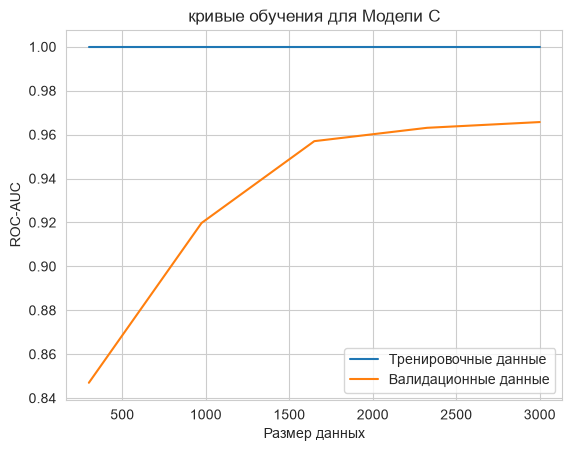

In [11]:
# TODO
# Вызов функции learning_curve (ставит оценки)
train_sizes, train_scores, test_scores = learning_curve(model_c, X_train, y_train, scoring='roc_auc', cv=5)
# Считаем среднее 
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

# Рисуем график
plt.plot(train_sizes, train_mean, label='Тренировочные данные')
plt.plot(train_sizes, test_mean, label='Валидационные данные')
# Оформление
plt.title('кривые обучения для Модели C')
plt.xlabel('Размер данных')
plt.ylabel('ROC-AUC')
plt.grid(True)
plt.legend()
plt.show()
# train_sizes - Размеры выборок (сколько строк бралось для обучения: например, 100, 300, 600...)
# train_scores- Оценки на обучающей части (значения метрики на train для каждого размера и фолда)
# test_scores- Оценки на проверочной части (значения метрики на validation для каждого размера и фолда)
# Фолд-(fold) переводится с английского как «складка», а в анализе данных означает просто «кусочек» или «часть» выборки.5 равных частей
# np.mean - np.mean — это функция из библиотеки NumPy, считающая среднее арифметическое.
# axis=1 — указание считать среднее вдоль строк (слева направо)


**Признаки переобучения:**
Признаки переобучения видны на графике на тренировочных данных показатель ROC-AUC 1.00 идеальный на протяжении всей выборки. Так же при малом объеме строк 300-1000 был огромный разрыв между тренировочными данными и обучающими. 
...

---
## Часть 5. Итоговое заключение (10 баллов)

> **TODO:** Заполните таблицу, сформулируйте рекомендацию и перечислите ограничения.

### Сводная таблица проблем

| Модель | Проблема | Проявление | Критичность |
|--------|----------|------------|--------------|
| A — Logistic Regression |Дисбаланс классов | пропускает 105 должников из 195 (Recall = 46.15%) | Высокая  |
| B — Random Forest | Утечка целевой переменной (Data Leakage) / критическое переобучение | Идеальные показатели по всем метрикам | Высокая |
| C — Gradient Boosting |Легкое переобучение | ROC-AUC на train = 1.00; на тесте пропускает 39 должников из 195 (Recall = 80.0%) | Умеренная |

### Рекомендация

Выбор базовой модели: рекомендовать к внедрению Модель C (Gradient Boosting) как наиболее точную и устойчивую на тесте (ROC-AUC ~0.96, Recall = 80%).
Калибровка порога классификации (Threshold Tuning): снизить порог отсечения со стандартного 0.5 до диапазона 0.3–0.4. Это позволит перехватить большую часть из 39 упущенных дефолтов ценой незначительного роста ложных отказов добросовестным клиентам.
Расследование Модели B: категорически запретить вывод в прод модели Random Forest до полного аудита признаков на предмет утечки целевой переменной (Data Leakage).
Регуляризация бустинга: ограничить максимальную глубину деревьев (max_depth) или повысить минимальное число объектов в листе (min_child_weight), чтобы сократить разрыв между идеальным train (1.00) и валидацией на кривых обучения.
Организация мониторинга: настроить регулярный отслеживающий контур (мониторинг метрик Recall/ROC-AUC и распределения входных признаков) с регламентом переобучения модели

### Ключевые ограничения
Сложность интерпретации («чёрный ящик»): в отличие от Модели A (логистической регрессии), где влияние каждого признака видно по весам, бустинг состоит из сотен деревьев. По закону и требованиям регулятора (ЦБ) банк обязан обосновать отказ клиенту, поэтому для Модели C обязательно внедрять дополнительные инструменты интерпретации

Склонность к локальному переобучению: бустинг очень чуток к шуму. Если в новых данных появятся выбросы или редкие сочетания признаков, модель может выдать неадекватно уверенный прогноз.

Вычислительные ресурсы и задержка (Latency): бустинг требует больше ресурсов и времени на инференс (расчет скоринга), чем простая формула логистической регрессии, что важно при потоковой онлайн-выдаче займов.

In [3]:
print("Работает")

Работает
